In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [3]:
data = pd.read_csv("supermarket.csv")
data

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Date,Time,Payment,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,1/5/2019,13:08,Ewallet,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3/8/2019,10:29,Cash,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,3/3/2019,13:23,Credit card,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,1/27/2019,20:33,Ewallet,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,2/8/2019,10:37,Ewallet,5.3
...,...,...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,C,Naypyitaw,Normal,Male,Health and beauty,40.35,1,1/29/2019,13:46,Ewallet,6.2
996,303-96-2227,B,Mandalay,Normal,Female,Home and lifestyle,97.38,10,3/2/2019,17:16,Ewallet,4.4
997,727-02-1313,A,Yangon,Member,Male,Food and beverages,31.84,1,2/9/2019,13:22,Cash,7.7
998,347-56-2442,A,Yangon,Normal,Male,Home and lifestyle,65.82,1,2/22/2019,15:33,Cash,4.1


In [4]:
data["Sales"] = data["Unit price"] * data["Quantity"]
data.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Date,Time,Payment,Rating,Sales
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,1/5/2019,13:08,Ewallet,9.1,522.83
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3/8/2019,10:29,Cash,9.6,76.40
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,3/3/2019,13:23,Credit card,7.4,324.31
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,1/27/2019,20:33,Ewallet,8.4,465.76
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,2/8/2019,10:37,Ewallet,5.3,604.17


In [5]:
data.shape

(1000, 13)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Invoice ID     1000 non-null   object 
 1   Branch         1000 non-null   object 
 2   City           1000 non-null   object 
 3   Customer type  1000 non-null   object 
 4   Gender         1000 non-null   object 
 5   Product line   1000 non-null   object 
 6   Unit price     1000 non-null   float64
 7   Quantity       1000 non-null   int64  
 8   Date           1000 non-null   object 
 9   Time           1000 non-null   object 
 10  Payment        1000 non-null   object 
 11  Rating         1000 non-null   float64
 12  Sales          1000 non-null   float64
dtypes: float64(3), int64(1), object(9)
memory usage: 101.7+ KB


In [7]:
data.describe()

,Unit price,Quantity,Rating,Sales
count,1000.000000,1000.000000,1000.00000,1000.00000
mean,55.672130,5.510000,6.97270,307.58738
std,26.494628,2.923431,1.71858,234.17651
min,10.080000,1.000000,4.00000,10.17000
25%,32.875000,3.000000,5.50000,118.49750
50%,55.230000,5.000000,7.00000,241.76000
75%,77.935000,8.000000,8.50000,448.90500
max,99.960000,10.000000,10.00000,993.00000


In [8]:
data.isnull().sum()

Invoice ID       0
Branch           0
City             0
Customer type    0
Gender           0
Product line     0
Unit price       0
Quantity         0
Date             0
Time             0
Payment          0
Rating           0
Sales            0
dtype: int64

In [13]:
dataset = data[["Unit price", "Sales"]]
dataset

,Unit price,Sales
0,74.69,522.83
1,15.28,76.40
2,46.33,324.31
3,58.22,465.76
4,86.31,604.17
...,...,...
995,40.35,40.35
996,97.38,973.80
997,31.84,31.84
998,65.82,65.82


{'whiskers': [<matplotlib.lines.Line2D at 0x2d81309c710>,
 'caps': [<matplotlib.lines.Line2D at 0x2d81309cd70>,
 'boxes': [<matplotlib.lines.Line2D at 0x2d81309c530>],
 'medians': [<matplotlib.lines.Line2D at 0x2d81309d1f0>],
 'fliers': [<matplotlib.lines.Line2D at 0x2d81309d4f0>],
 'means': []}

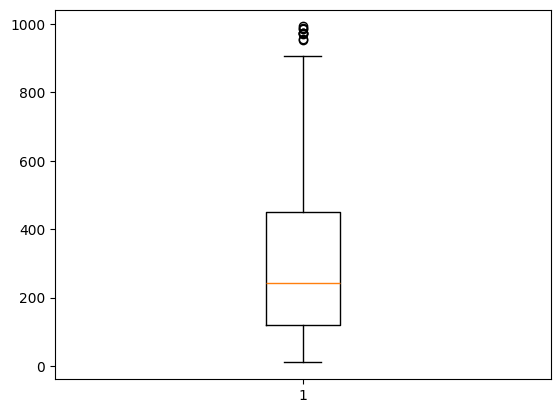

In [14]:
plt.boxplot(dataset["Sales"])

In [15]:
q1 = np.percentile(dataset["Sales"], 25)
q3 = np.percentile(dataset["Sales"], 75)

iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

dataset = dataset[(dataset["Sales"] > lower) & (dataset["Sales"] < upper)]
dataset

,Unit price,Sales
0,74.69,522.83
1,15.28,76.40
2,46.33,324.31
3,58.22,465.76
4,86.31,604.17
...,...,...
994,60.95,60.95
995,40.35,40.35
997,31.84,31.84
998,65.82,65.82


In [12]:
dataset.isnull().sum()

Unit price    0
Sales         0
dtype: int64

In [16]:
dataset.corr()

,Unit price,Sales
Unit price,1.000000,0.623355
Sales,0.623355,1.000000


In [22]:
dataset[["Sales"]]

,Sales
0,522.83
1,76.40
2,324.31
3,465.76
4,604.17
...,...
994,60.95
995,40.35
997,31.84
998,65.82


In [23]:
data = pd.read_csv("supermarket.csv")
data["Sales"] = data["Unit price"] * data["Quantity"]
dataset = data[["Unit price", "Sales"]]

q1 = np.percentile(dataset["Sales"], 25)
q3 = np.percentile(dataset["Sales"], 75)

iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

dataset = dataset[(dataset["Sales"] > lower) & (dataset["Sales"] < upper)]

# Membagi dataset menjadi training dan testing set
X_train, X_test, y_train, y_test = train_test_split(dataset[["Sales"]], dataset["Sales"], test_size=0.2, random_state=42)

# Membuat dan melatih model regresi linier
model = LinearRegression()
model.fit(X_train, y_train)

# Melakukan prediksi
y_pred = model.predict(X_test)

plt.scatter(dataset[["Sales"]], dataset["Sales"], color='blue', label='Actual Data')  # Data asli
plt.plot(X, model.predict(X), color='red', label='Regression Line')  # Garis regresi
plt.xlabel('Petal Width')
plt.ylabel('Petal Length')
plt.title('Linear Regression on Iris Dataset')
plt.legend()
plt.show()

array([ 18.28,  46.96, 145.5 , 138.66,  42.47,  92.04,  15.34, 372.78,
       183.66, 214.55, 439.32, 448.26, 894.8 , 878.7 , 724.24, 579.12,
       214.3 , 898.38, 441.36, 285.11, 114.9 ,  88.45,  35.82, 193.44,
        75.88,  92.78, 319.9 , 125.74, 295.8 ,  84.16,  95.36, 819.5 ,
       115.78, 327.06, 291.  , 436.85, 280.62,  53.78, 662.13, 119.98,
       240.24, 172.8 , 470.65, 587.6 ,  57.92, 177.36, 119.72, 247.4 ,
       389.04, 206.37, 580.  , 339.57, 378.9 ,  69.4 ,  83.08, 155.82,
       144.78, 461.88, 839.34, 419.94, 137.22, 746.  , 581.98, 598.98,
       204.7 , 240.96, 720.16, 101.43, 167.54,  66.94, 410.9 , 585.66,
        73.1 , 336.35, 356.56, 222.4 , 475.93,  54.95, 244.2 , 235.8 ,
       181.1 , 906.5 , 158.1 ,  88.04, 755.92, 775.6 ,  68.58, 543.6 ,
       263.76, 112.62,  66.35, 388.96,  76.82, 631.71, 674.59, 171.81,
       382.6 , 378.3 , 874.98, 133.26, 558.7 , 243.  , 795.51, 169.68,
        53.45, 511.42, 179.05,  39.42,  68.16, 603.8 ,  91.35, 131.55,
      

In [ ]:
plt.scatter(dataset[["Sales"]], dataset["Sales"], color='blue', label='Actual Data')  # Data asli
plt.plot(X, model.predict(X), color='red', label='Regression Line')  # Garis regresi
plt.xlabel('Petal Width')
plt.ylabel('Petal Length')
plt.title('Linear Regression on Iris Dataset')
plt.legend()
plt.show()

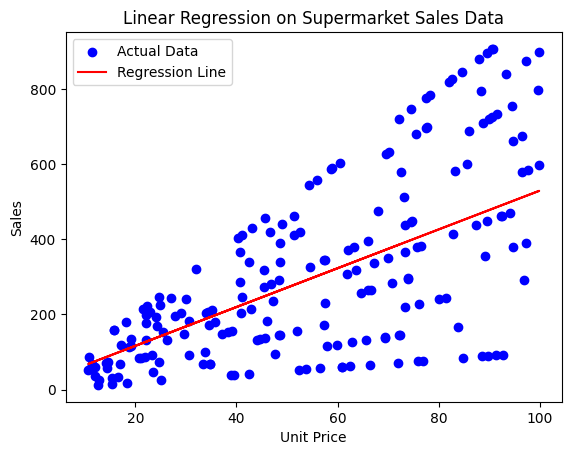

In [25]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# Membaca data dari file CSV
data = pd.read_csv("supermarket.csv")

# Menghitung total penjualan
data["Sales"] = data["Unit price"] * data["Quantity"]

# Memilih kolom yang relevan
dataset = data[["Unit price", "Sales"]]

# Menghitung kuartil pertama dan ketiga
q1 = np.percentile(dataset["Sales"], 25)
q3 = np.percentile(dataset["Sales"], 75)

# Menghitung Interquartile Range (IQR)
iqr = q3 - q1

# Menentukan batas bawah dan atas untuk mendeteksi outlier
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

# Menghilangkan data outlier
dataset = dataset[(dataset["Sales"] > lower) & (dataset["Sales"] < upper)]

# Membagi dataset menjadi training dan testing set
X_train, X_test, y_train, y_test = train_test_split(dataset[["Unit price"]], dataset["Sales"], test_size=0.2, random_state=42)

# Membuat dan melatih model regresi linier
model = LinearRegression()
model.fit(X_train, y_train)

# Melakukan prediksi
y_pred = model.predict(X_test)

# Menampilkan hasil regresi dengan plot
plt.scatter(X_test, y_test, color='blue', label='Actual Data')  # Data asli
plt.plot(X_test, y_pred, color='red', label='Regression Line')  # Garis regresi
plt.xlabel('Unit Price')
plt.ylabel('Sales')
plt.title('Linear Regression on Supermarket Sales Data')
plt.legend()
plt.show()


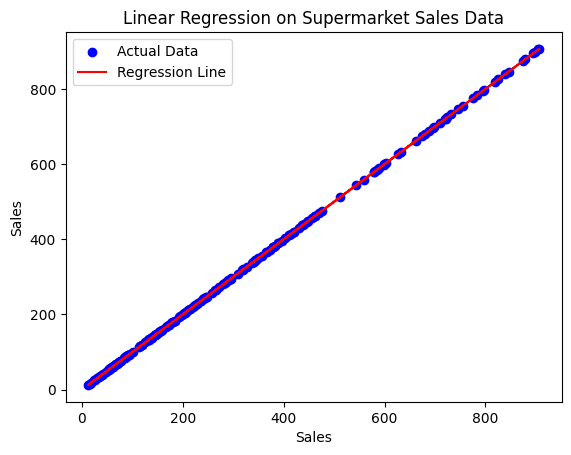

In [26]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# Membaca data dari file CSV
data = pd.read_csv("supermarket.csv")

# Menghitung total penjualan
data["Sales"] = data["Unit price"] * data["Quantity"]

# Memilih kolom yang relevan
dataset = data[["Sales"]]

# Menghitung kuartil pertama dan ketiga
q1 = np.percentile(dataset["Sales"], 25)
q3 = np.percentile(dataset["Sales"], 75)

# Menghitung Interquartile Range (IQR)
iqr = q3 - q1

# Menentukan batas bawah dan atas untuk mendeteksi outlier
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

# Menghilangkan data outlier
dataset = dataset[(dataset["Sales"] > lower) & (dataset["Sales"] < upper)]

# Membagi dataset menjadi training dan testing set
X_train, X_test, y_train, y_test = train_test_split(dataset[["Sales"]], dataset["Sales"], test_size=0.2, random_state=42)

# Membuat dan melatih model regresi linier
model = LinearRegression()
model.fit(X_train, y_train)

# Melakukan prediksi
y_pred = model.predict(X_test)

# Menampilkan hasil regresi dengan plot
plt.scatter(X_test, y_test, color='blue', label='Actual Data')  # Data asli
plt.plot(X_test, y_pred, color='red', label='Regression Line')  # Garis regresi
plt.xlabel('Sales')
plt.ylabel('Sales')
plt.title('Linear Regression on Supermarket Sales Data')
plt.legend()
plt.show()


MAPE: 0.91
MSE: 33147.14
R^2: 0.43


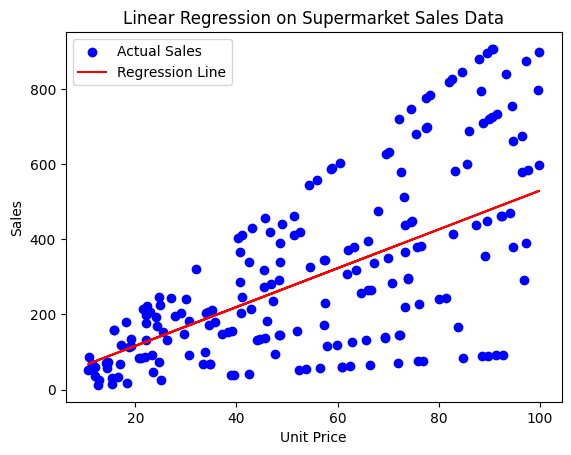

In [27]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# 1. Membaca data dari file CSV
data = pd.read_csv("supermarket.csv")

# 2. Menghitung total penjualan (Sales)
data["Sales"] = data["Unit price"] * data["Quantity"]

# Memilih kolom yang relevan untuk model
dataset = data[["Unit price", "Sales"]]

# 3. Menghitung kuartil pertama dan ketiga untuk menghilangkan outliers
q1 = np.percentile(dataset["Sales"], 25)
q3 = np.percentile(dataset["Sales"], 75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

# Menghilangkan data outliers
dataset = dataset[(dataset["Sales"] > lower) & (dataset["Sales"] < upper)]

# 4. Membagi dataset menjadi training dan testing set
X_train, X_test, y_train, y_test = train_test_split(dataset[["Unit price"]], dataset["Sales"], test_size=0.2, random_state=42)

# 5. Membuat dan melatih model regresi linier
model = LinearRegression()
model.fit(X_train, y_train)

# 6. Melakukan prediksi pada data testing
y_pred = model.predict(X_test)

# 7. Evaluasi model (misalnya dengan MSE, R^2, atau MAPE)
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error, r2_score

mape = mean_absolute_percentage_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'MAPE: {mape:.2f}')
print(f'MSE: {mse:.2f}')
print(f'R^2: {r2:.2f}')

# 8. Visualisasi hasil prediksi dengan plot
plt.scatter(X_test, y_test, color='blue', label='Actual Sales')  # Data asli
plt.plot(X_test, y_pred, color='red', label='Regression Line')  # Garis regresi
plt.xlabel('Unit Price')
plt.ylabel('Sales')
plt.title('Linear Regression on Supermarket Sales Data')
plt.legend()
plt.show()
